# 03-3. 관측값 추정: 검증 지점 평가와 저장

03(관측값 추정 모델)의 4~6장. 03-1·03-2에서 고른 최종 방법(앙상블 + B3)을 학습 지점 전체로 다시 학습해 검증 지점 3곳에서 평가하고,
모델과 추정값을 저장한다.

03 구성: 03-1 후보 모델·교차검증(1~2장) · 03-2 추가 실험·RWIS 보간 개선(3장) · **03-3 검증 지점 평가·시각화·저장(4~6장)**

- 입력: 02-2의 지점 변수, 03-1의 교차검증 예측·설정 (`estimation_oof.parquet`, `estimation_cv.json`),
  03-2의 B3 추정값·최종 앙상블 구성 (`estimation_b3.parquet`, `estimation_final.json`)
- 출력: 추정 모델(`model/road_temp_*`), 검증 지점 성능·추정값(`data/results/`), 전 지점 추정 노면온도(`data/processed/station_estimates.parquet`, 04·05에서 사용)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import json
import time
import warnings

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib import font_manager
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})

for d in [config.RESULT_DIR, config.MODEL_DIR, config.FIGURE_DIR]:
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
TARGET = "rst"  # 노면온도

In [3]:
sf = pd.read_parquet(config.PROCESSED_DIR / "station_features.parquet")
stations = pd.read_parquet(config.PROCESSED_DIR / "stations.parquet").set_index("stn")
FEATURES = json.load(open(config.PROCESSED_DIR / "features.json", encoding="utf-8"))["features"]

# 03-1에서 정한 설정
cv = json.load(open(config.PROCESSED_DIR / "estimation_cv.json", encoding="utf-8"))
CORE, LGB_PARAMS, best_iter = cv["core"], cv["lgb_params"], cv["best_iter"]

def split_holdout(df):
    """검증 지점(config.HOLDOUT_STATIONS)을 학습 데이터에서 분리한다 (03-1의 1장과 같음)."""
    is_holdout = df["stn"].isin(config.HOLDOUT_STATIONS)
    return df[~is_holdout].reset_index(drop=True), df[is_holdout].reset_index(drop=True)


train_all, holdout = split_holdout(sf)
train = train_all.dropna(subset=[TARGET])

# 03-1의 학습 지점 교차검증 예측
oof = pd.read_parquet(config.PROCESSED_DIR / "estimation_oof.parquet")
assert oof["stn"].equals(train_all["stn"]) and oof["time"].equals(train_all["time"])
oof = oof.drop(columns=["stn", "time"])
BASE_ENSEMBLE = cv["ensemble"]  # 03-1의 기본 앙상블

# 03-2의 3-6에서 정한 최종 앙상블과 B3(밑그림 + 그날의 오차 크리깅) 추정값.
# B3는 학습 지점에서는 교차검증 예측, 검증 지점에서는 학습 지점 14곳으로 만든 값이다.
final = json.load(open(config.PROCESSED_DIR / "estimation_final.json", encoding="utf-8"))
ENSEMBLE, FINAL, B3_NAME = final["ensemble"], final["final"], final["b3"]
BASE_METHODS = cv["base_methods"] + [B3_NAME, FINAL]
b3 = pd.read_parquet(config.PROCESSED_DIR / "estimation_b3.parquet").rename(columns={"b3": B3_NAME})
oof[B3_NAME] = train_all[["stn", "time"]].merge(b3, on=["stn", "time"], how="left")[B3_NAME].to_numpy()
oof[FINAL] = oof[ENSEMBLE].mean(axis=1)
holdout = holdout.merge(b3, on=["stn", "time"], how="left", validate="one_to_one")

print(f"최종 방법: {FINAL} (구성: {' + '.join(ENSEMBLE)})")

최종 방법: 앙상블+B3 (구성: LightGBM(핵심) + Ridge(핵심) + B1 주변 노면온도 + B3 밑그림+크리깅)


In [4]:
def make_ridge():
    """Ridge(핵심) (03-1의 2장과 같음)."""
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=1.0))


def regression_scores(y_true, y_pred):
    """관측값 추정 성능 {"N", "BIAS", "MAE", "RMSE"}. BIAS = 평균(추정 - 관측). (03-1의 2장과 같음)"""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = ~(np.isnan(y_true) | np.isnan(y_pred))
    err = y_pred[ok] - y_true[ok]
    return {"N": int(ok.sum()), "BIAS": err.mean(), "MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean())}


def score_table(df, preds):
    """지점별 성능 + 지점 평균 행."""
    rows = []
    for method in preds.columns:
        for stn, idx in df.groupby("stn").groups.items():
            rows.append({"stn": stn, "지점명": stations.loc[stn, "name"], "방법": method,
                         **regression_scores(df.loc[idx, TARGET], preds.loc[idx, method])})
    scores = pd.DataFrame(rows)
    mean = scores.groupby("방법", sort=False)[["N", "BIAS", "MAE", "RMSE"]].mean().reset_index()
    mean.insert(0, "지점명", f"{df['stn'].nunique()}개 지점 평균")
    mean.insert(0, "stn", "mean")
    return pd.concat([scores, mean], ignore_index=True)

## 4. 검증 지점 평가

학습 지점 전체로 최종 모델을 다시 학습하고 검증 지점을 예측한다.

In [5]:
def train_estimator(train_df):
    """앙상블 구성 모델(LightGBM 핵심, Ridge 핵심)을 학습한다. 검증 지점은 train_df에 없어야 한다."""
    assert not train_df["stn"].isin(config.HOLDOUT_STATIONS).any()
    params = dict(LGB_PARAMS["LightGBM(핵심)"], n_estimators=best_iter["LightGBM(핵심)"])
    lgbm = lgb.LGBMRegressor(**params).fit(train_df[CORE], train_df[TARGET])
    ridge = make_ridge().fit(train_df[CORE], train_df[TARGET])
    return {"lgbm": lgbm, "ridge": ridge}


def predict_estimator(models, df):
    """구간 또는 검증 지점의 노면온도를 추정한다 (구성 모델별 예측과 앙상블). B3는 03-2에서 만든 값을 쓴다."""
    out = pd.DataFrame(index=df.index)
    out["LightGBM(핵심)"] = models["lgbm"].predict(df[CORE])
    out["Ridge(핵심)"] = models["ridge"].predict(df[CORE])
    out["B1 주변 노면온도"] = df["nbr_rst"]
    out[B3_NAME] = df[B3_NAME]
    out["앙상블"] = out[BASE_ENSEMBLE].mean(axis=1)
    out[FINAL] = out[ENSEMBLE].mean(axis=1)
    return out


t0 = time.time()
models = train_estimator(train)
full = lgb.LGBMRegressor(**dict(LGB_PARAMS["LightGBM(전체)"], n_estimators=best_iter["LightGBM(전체)"]))
full.fit(train[FEATURES], train[TARGET])
print(f"최종 모델 학습 {time.time() - t0:.0f}s")

pred_ho = predict_estimator(models, holdout)
pred_ho["LightGBM(전체)"] = full.predict(holdout[FEATURES])
pred_ho["B0 보간 기온"] = holdout["ta"]
pred_ho["B2 기온+노면편차"] = holdout["rst_phys"]
pred_ho = pred_ho[BASE_METHODS]
holdout["rst_est"] = pred_ho[FINAL].astype("float32")
train_all["rst_est"] = oof[FINAL].astype("float32")

최종 모델 학습 8s


### 검증 지점 성능

- BIAS = 평균(추정 - 관측), MAE = 평균|추정 - 관측|, RMSE = √평균(추정 - 관측)²
- 지점별 값과 세 지점 평균을 제시한다. 10분 단위 전체 기간(240일) 기준이다.

In [6]:
holdout_scores = score_table(holdout, pred_ho)
holdout_scores[holdout_scores["방법"] == FINAL].round(3)

,stn,지점명,방법,N,BIAS,MAE,RMSE
24,12410,부곡교(도),앙상블+B3,34559.0,-0.547,0.679,0.918
25,23402,해전(도),앙상블+B3,34559.0,-0.764,0.807,1.005
26,33411,삼봉(도),앙상블+B3,34559.0,-0.011,0.556,0.753
35,mean,3개 지점 평균,앙상블+B3,34559.0,-0.440,0.680,0.892


모든 후보의 검증 지점 성능 (참고, 선택에는 쓰지 않음)

In [7]:
holdout_scores.pivot(index="방법", columns="지점명", values="RMSE").loc[BASE_METHODS].round(3)

지점명,3개 지점 평균,부곡교(도),삼봉(도),해전(도)
방법,,,,
B0 보간 기온,3.405,3.417,3.152,3.645
B1 주변 노면온도,0.987,0.933,1.015,1.013
B2 기온+노면편차,0.952,0.887,0.981,0.987
LightGBM(전체),1.284,1.322,1.073,1.457
LightGBM(핵심),0.999,1.022,0.863,1.112
Ridge(핵심),0.994,0.993,0.871,1.118
앙상블,0.937,0.925,0.858,1.028
B3 밑그림+크리깅,1.083,1.073,1.092,1.083
앙상블+B3,0.892,0.918,0.753,1.005


B3를 더한 최종 앙상블(0.892°C)은 03-1의 기본 앙상블(0.937°C)보다 세 지점 모두에서 낮다 (부곡교 0.925 → 0.918, 삼봉 0.858 → 0.753, 해전 1.028 → 1.005). B3 단독(1.083°C)은 B1보다 나쁘지만, 이웃의 지문을 그대로 옮기는 B1과 오차 양상이 달라 평균하면 서로의 오차를 줄인다 (03-2의 3-6-5). 평지인 부곡교(-0.55°C)·해전(-0.76°C)을 실제보다 낮게 추정하는 경향은 그대로 남아 있다 (세 지점 평균 BIAS -0.44°C).

결빙 판단에는 영하 근처의 정확도가 중요하므로, 관측 노면온도 2°C 이하만 따로 본다.

In [8]:
cold = holdout[TARGET] <= 2
cold_scores = score_table(holdout[cold], pred_ho[cold])
cold_scores.pivot(index="방법", columns="지점명", values="RMSE").loc[BASE_METHODS].round(3)

지점명,3개 지점 평균,부곡교(도),삼봉(도),해전(도)
방법,,,,
B0 보간 기온,2.307,1.968,2.642,2.312
B1 주변 노면온도,0.804,0.703,0.761,0.948
B2 기온+노면편차,0.753,0.629,0.713,0.918
LightGBM(전체),0.977,0.898,0.991,1.041
LightGBM(핵심),0.710,0.619,0.716,0.795
Ridge(핵심),0.708,0.616,0.669,0.838
앙상블,0.698,0.590,0.672,0.833
B3 밑그림+크리깅,0.854,0.801,1.031,0.729
앙상블+B3,0.653,0.586,0.597,0.775


노면 2°C 이하에서도 B3를 더한 최종 앙상블이 가장 낮다 (기본 앙상블 0.698 → 0.653°C).

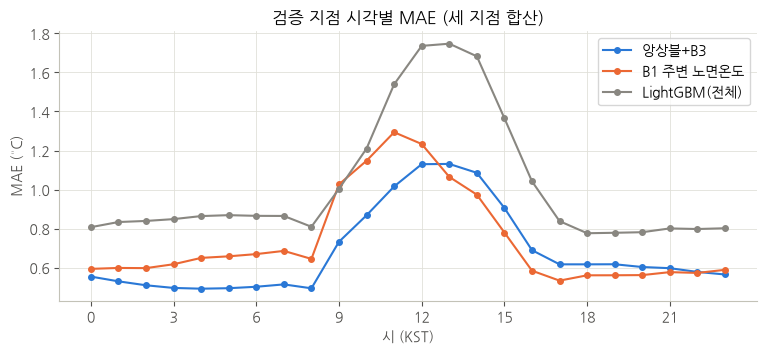

In [9]:
hours = holdout["time"].dt.hour
fig, ax = plt.subplots(figsize=(9, 3.5))
for method, color in [(FINAL, "#2a78d6"), ("B1 주변 노면온도", "#eb6834"), ("LightGBM(전체)", "#898781")]:
    mae = (pred_ho[method] - holdout[TARGET]).abs().groupby(hours).mean()
    ax.plot(mae.index, mae.values, marker="o", markersize=4, color=color, label=method)
ax.set_xlabel("시 (KST)")
ax.set_ylabel("MAE (°C)")
ax.set_xticks(range(0, 24, 3))
ax.set_title("검증 지점 시각별 MAE (세 지점 합산)")
ax.legend()
plt.show()

오차는 낮 시간(10~15시)에 크다. 햇빛을 받은 노면의 가열 정도가 지점마다 다르기 때문이다 (일사·차폐, 01-7의 13-6).
결빙이 주로 생기는 야간·새벽에는 오차가 작다. 검증 지점에서도 B0(보간 기온)의 RMSE는 3.4°C로, 최종 방법(0.89°C)의 3배가 넘는다.

## 5. 결과 시각화

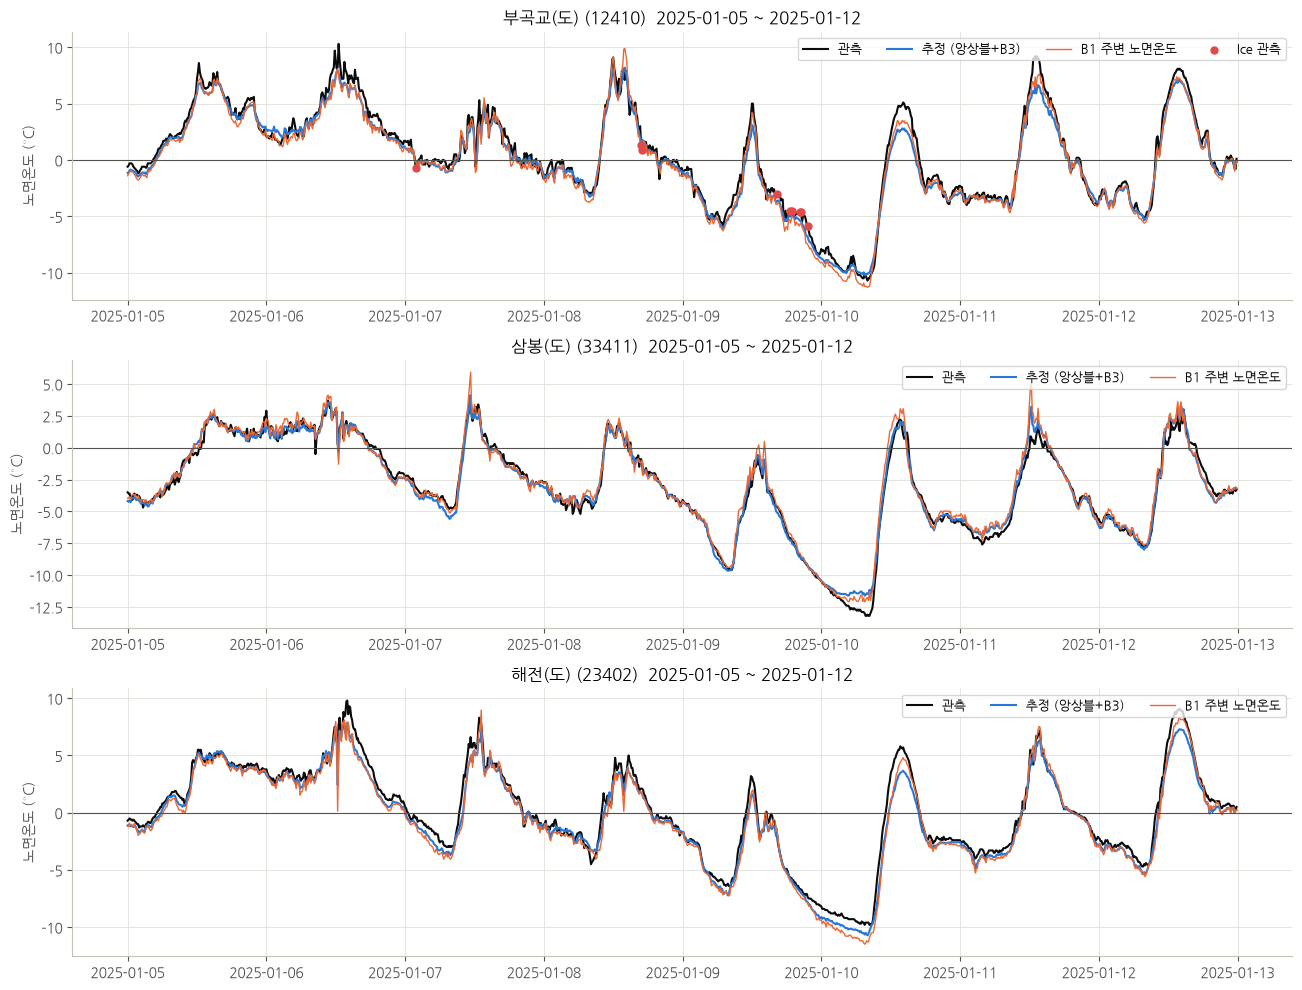

In [10]:
def plot_estimation(df, station_id, start, end, ax=None):
    """검증 지점의 실제 관측값과 추정값을 비교한다."""
    g = df[df["stn"] == station_id].set_index("time").loc[start:end]
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 3.5))
    ax.plot(g.index, g[TARGET], color="#0b0b0b", label="관측")
    ax.plot(g.index, g["rst_est"], color="#2a78d6", label=f"추정 ({FINAL})")
    ax.plot(g.index, g["nbr_rst"], color="#eb6834", linewidth=1, label="B1 주변 노면온도")
    ice = g.index[g["ice"] == 1]
    if len(ice):
        ax.scatter(ice, g.loc[ice, TARGET], color="#e34948", s=25, zorder=5, label="Ice 관측")
    ax.axhline(0, color="#52514e", linewidth=0.8)
    ax.set_ylabel("노면온도 (°C)")
    ax.set_title(f"{stations.loc[station_id, 'name']} ({station_id})  {start} ~ {end}")
    ax.legend(ncol=4, fontsize=9, loc="upper right")
    return ax


fig, axes = plt.subplots(3, 1, figsize=(13, 10))
for ax, stn in zip(axes, config.HOLDOUT_STATIONS):
    plot_estimation(holdout, stn, "2025-01-05", "2025-01-12", ax=ax)
plt.tight_layout()
fig.savefig(config.FIGURE_DIR / "estimation_holdout_timeseries.png", dpi=150, bbox_inches="tight")
plt.show()

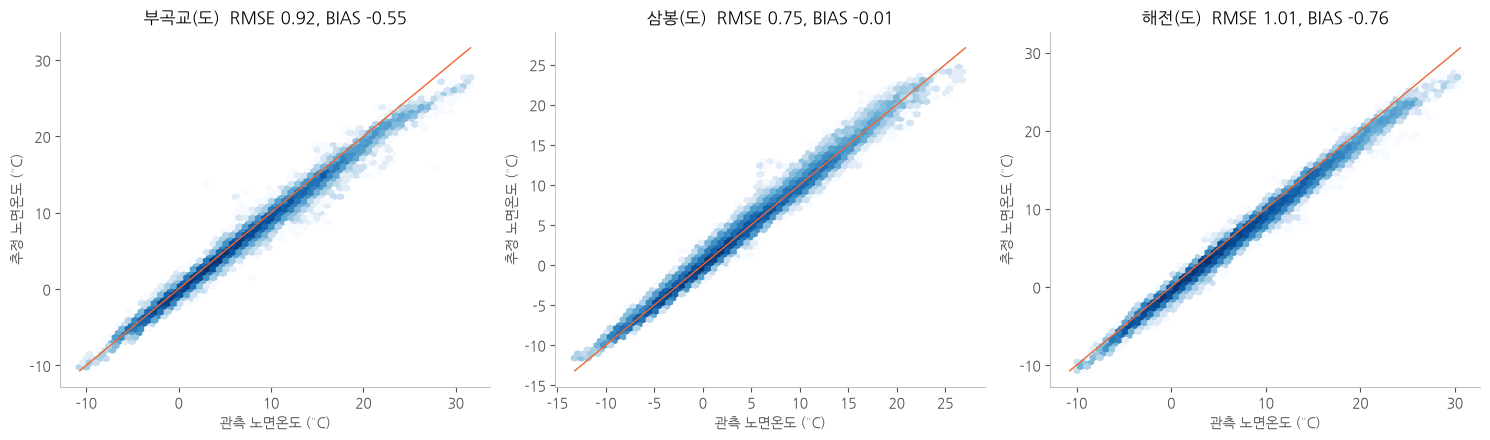

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, stn in zip(axes, config.HOLDOUT_STATIONS):
    g = holdout[holdout["stn"] == stn].dropna(subset=[TARGET, "rst_est"])
    ax.hexbin(g[TARGET], g["rst_est"], gridsize=60, cmap="Blues", mincnt=1, bins="log")
    lim = [min(g[TARGET].min(), g["rst_est"].min()), max(g[TARGET].max(), g["rst_est"].max())]
    ax.plot(lim, lim, color="#eb6834", linewidth=1)
    s = regression_scores(g[TARGET], g["rst_est"])
    ax.set_title(f"{stations.loc[stn, 'name']}  RMSE {s['RMSE']:.2f}, BIAS {s['BIAS']:+.2f}")
    ax.set_xlabel("관측 노면온도 (°C)")
    ax.set_ylabel("추정 노면온도 (°C)")
    ax.grid(False)
plt.tight_layout()
fig.savefig(config.FIGURE_DIR / "estimation_holdout_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

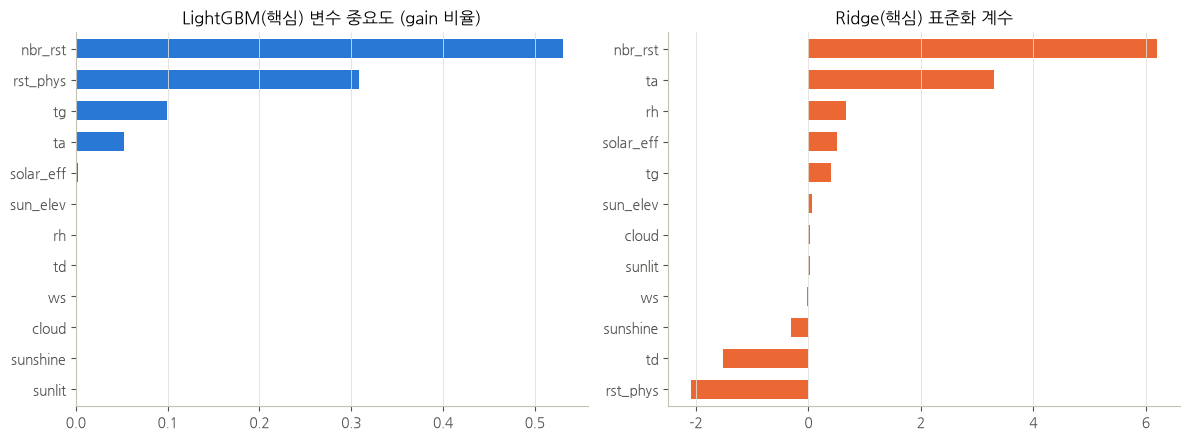

In [12]:
imp = pd.Series(models["lgbm"].booster_.feature_importance("gain"), index=CORE)
coef = pd.Series(models["ridge"][-1].coef_, index=CORE)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
(imp / imp.sum()).sort_values().plot.barh(ax=axes[0], width=0.6)
axes[0].set_title("LightGBM(핵심) 변수 중요도 (gain 비율)")
coef.sort_values().plot.barh(ax=axes[1], width=0.6, color="#eb6834")
axes[1].set_title("Ridge(핵심) 표준화 계수")
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

두 모델 모두 주변 RWIS 노면온도(`nbr_rst`)를 가장 크게 쓰고, 보간 기온·지면온도·이슬점으로 보정한다.
Ridge는 서로 상관이 큰 변수(`nbr_rst`와 `rst_phys`, `ta`와 `td`)가 함께 들어가 있어 계수의 부호보다 크기 위주로 본다.

## 6. 저장

- `model/road_temp_lgbm.txt`, `model/road_temp_ridge.joblib`: 앙상블 구성 모델, `model/road_temp_meta.json`: 변수·반복 횟수·앙상블 구성
  (B3의 밑그림 계수·지문·준변동함수는 03-2가 `model/road_temp_b3.json`에, 구간 추정값은 `data/processed/segment_b3.parquet`에 저장한다)
- `data/results/estimation_scores.csv`: 검증 지점 성능 (지점별 + 세 지점 평균, 전 후보)
- `data/results/estimation_holdout_10min.csv`: 검증 지점 10분 단위 관측·추정값
- `data/processed/station_estimates.parquet`: 전 지점 추정 노면온도 (학습 지점은 교차검증 예측) → 04에서 사용

교차검증 성능(`estimation_cv_scores.csv`)은 03-1에서, 3장의 실험 결과 표는 03-2에서 저장한다.

In [13]:
models["lgbm"].booster_.save_model(config.MODEL_DIR / "road_temp_lgbm.txt")
joblib.dump(models["ridge"], config.MODEL_DIR / "road_temp_ridge.joblib")
with open(config.MODEL_DIR / "road_temp_meta.json", "w", encoding="utf-8") as f:
    json.dump({"target": TARGET, "method": FINAL, "features": CORE, "ensemble": ENSEMBLE, "b3": B3_NAME,
               "b3_params": "road_temp_b3.json", "b3_segments": "data/processed/segment_b3.parquet",
               "lgbm_params": LGB_PARAMS["LightGBM(핵심)"], "lgbm_iterations": best_iter["LightGBM(핵심)"],
               "train_stations": sorted(int(s) for s in train_all["stn"].unique()),
               "holdout_stations": list(config.HOLDOUT_STATIONS)}, f, ensure_ascii=False, indent=2)

holdout_scores.round(4).to_csv(config.RESULT_DIR / "estimation_scores.csv", index=False, encoding="utf-8-sig")
(holdout[["stn", "time", TARGET, "rst_est"]].rename(columns={TARGET: "rst_obs"}).round(2)
 .to_csv(config.RESULT_DIR / "estimation_holdout_10min.csv", index=False, encoding="utf-8-sig"))
pd.concat([train_all, holdout])[["stn", "time", "rst_est"]].to_parquet(
    config.PROCESSED_DIR / "station_estimates.parquet", index=False)
print("저장 완료")

저장 완료
